# Movie Recommendation Systems

Regularized matrix factorization and a genre-based recommender on MovieLens small.

See [project notes](docs/movie-recommendations.md) for setup, methods, and limitations.

Saved outputs are from the original local exploration; restart the kernel and run all cells for a fresh result.


In [4]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

In [5]:
import requests
import zipfile
import io

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded and extracted!")

Dataset downloaded and extracted!


In [6]:
ratings=pd.read_csv('ml-latest-small/ratings.csv')
movies=pd.read_csv('ml-latest-small/movies.csv')

print(ratings.head())
print(ratings.shape)
print("Users:", ratings['userId'].nunique(), "| Movies:", ratings['movieId'].nunique())

   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
(100836, 4)
Users: 610 | Movies: 9724


In [9]:
n_users=ratings['userId'].nunique()
n_movies=ratings['movieId'].nunique()

# Build mapping since movieId/userId values may not be sequential 0..n
user_ids=ratings['userId'].unique()
movie_ids=ratings['movieId'].unique()
user_to_idx = {u: i for i, u in enumerate(user_ids)}
movie_to_idx = {m: i for i, m in enumerate(movie_ids)}

r=np.zeros((n_movies, n_users))            # the ratings matrix
Y_mask = np.zeros((n_movies, n_users))     # 1 if rated, 0 if not — this matters a lot

for _, row in ratings.iterrows():
    m_idx=movie_to_idx[row['movieId']]
    u_idx=user_to_idx[row['userId']]
    r[m_idx, u_idx]=row['rating']
    Y_mask[m_idx, u_idx]=1

In [10]:
n_features=10
X=np.random.randn(n_movies, n_features)*0.1
theta=np.random.randn(n_users, n_features)*0.1

In [19]:
def cost_function(X, theta, r, Y_mask, lambda_reg=1.0):
    predictions=X@theta.T
    error=(predictions-r)*Y_mask

    squared_error_cost=0.5*np.sum(error**2)

    #Regularisation
    reg_cost=(lambda_reg/2)*(np.sum(X**2)+np.sum(theta**2))

    return squared_error_cost+reg_cost

def compute_gradient(X, theta, r, Y_mask, lambda_reg=1.0):
    predictions=X@theta.T
    error=(predictions-r)*Y_mask

    X_grad=error@theta+lambda_reg*X
    theta_grad=error.T@X+lambda_reg*theta

    return X_grad, theta_grad

In [24]:
def train(X, theta, r, Y_mask, lambda_reg=2.0, learning_rate=0.0001, epochs=200):
    costs=[]
    for epoch in range(epochs):
        cost=cost_function(X, theta, r, Y_mask, lambda_reg)
        X_grad, theta_grad=compute_gradient(X, theta, r, Y_mask, lambda_reg)
        X-=learning_rate*X_grad
        theta-=learning_rate*theta_grad

        costs.append(cost)
        if epochs%20==0:
            print(f"Epoch {epoch}, Cost {cost:.2f}")
    return X, theta, costs

In [29]:
movie_means = np.zeros(n_movies)
for i in range(n_movies):
    rated = Y_mask[i, :] == 1
    if rated.sum() > 0:
        movie_means[i] = r[i, rated].mean()

R_normalized = (r - movie_means[:, np.newaxis]) * Y_mask

X, theta, costs = train(X, theta, R_normalized, Y_mask, lambda_reg=1.0, learning_rate=0.0001, epochs=200)

Epoch 0, Cost 728886.61
Epoch 1, Cost 563556.03
Epoch 2, Cost 459054.38
Epoch 3, Cost 387602.49
Epoch 4, Cost 335941.52
Epoch 5, Cost 296989.04
Epoch 6, Cost 266640.94
Epoch 7, Cost 242366.76
Epoch 8, Cost 222527.72
Epoch 9, Cost 206019.23
Epoch 10, Cost 192071.57
Epoch 11, Cost 180133.08
Epoch 12, Cost 169798.68
Epoch 13, Cost 160764.63
Epoch 14, Cost 152798.94
Epoch 15, Cost 145721.51
Epoch 16, Cost 139390.46
Epoch 17, Cost 133692.58
Epoch 18, Cost 128536.47
Epoch 19, Cost 123847.52
Epoch 20, Cost 119564.25
Epoch 21, Cost 115635.57
Epoch 22, Cost 112018.65
Epoch 23, Cost 108677.30
Epoch 24, Cost 105580.79
Epoch 25, Cost 102702.81
Epoch 26, Cost 100020.70
Epoch 27, Cost 97514.86
Epoch 28, Cost 95168.25
Epoch 29, Cost 92965.95
Epoch 30, Cost 90894.89
Epoch 31, Cost 88943.53
Epoch 32, Cost 87101.64
Epoch 33, Cost 85360.17
Epoch 34, Cost 83711.02
Epoch 35, Cost 82146.95
Epoch 36, Cost 80661.47
Epoch 37, Cost 79248.74
Epoch 38, Cost 77903.48
Epoch 39, Cost 76620.92
Epoch 40, Cost 75396.74

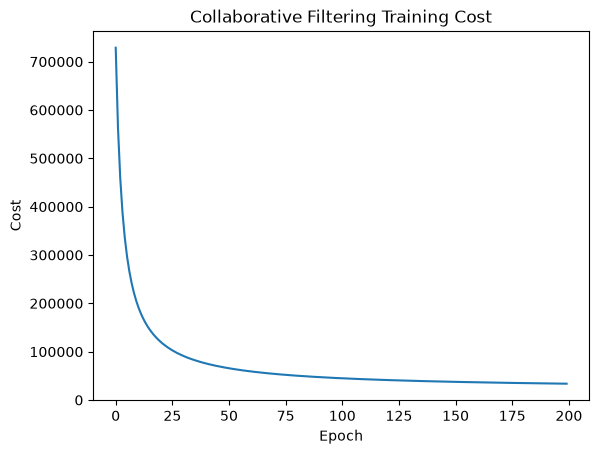

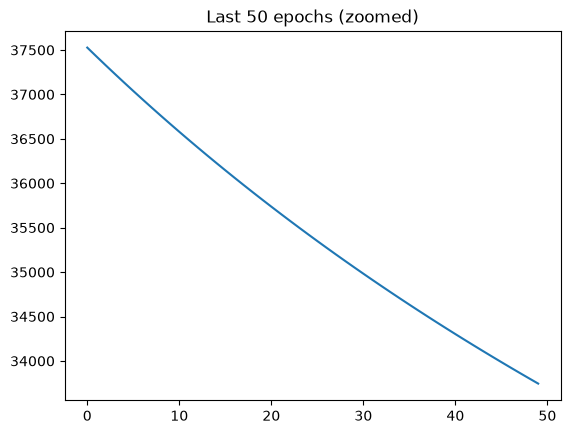

In [30]:
plt.plot(costs)
plt.xlabel('Epoch')
plt.ylabel('Cost')
plt.title('Collaborative Filtering Training Cost')
plt.show()

# zoom into the last 50 epochs to check for residual oscillation
plt.plot(costs[-50:])
plt.title('Last 50 epochs (zoomed)')
plt.show()

In [23]:
# simple content-based: represent each movie as a genre vector, recommend similar movies
# to what a user has rated highly, using cosine similarity

def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-8)

# one-hot encode genres (pipe-separated string, e.g. "Action|Adventure|Sci-Fi")
all_genres = set()
for g in movies['genres']:
    all_genres.update(g.split('|'))
all_genres = sorted(all_genres)

genre_to_idx = {g: i for i, g in enumerate(all_genres)}
genre_matrix = np.zeros((len(movies), len(all_genres)))

for i, g_string in enumerate(movies['genres']):
    for g in g_string.split('|'):
        genre_matrix[i, genre_to_idx[g]] = 1

In [35]:
predictions = X @ theta.T

def recommend_for_user(user_id, predictions, Y_mask, movie_to_idx, idx_to_movie, top_n=10):
    u_idx=user_to_idx[user_id]
    user_predictions=predictions[:, u_idx]

    already_rated=Y_mask[:, u_idx]==1
    user_predictions_unrated = np.where(already_rated, -np.inf, user_predictions)
    
    top_movie_indices = np.argsort(user_predictions_unrated)[::-1][:top_n]
    return [idx_to_movie[i] for i in top_movie_indices]

In [45]:
# check how many ratings each recommended movie actually has
movie_rating_counts = ratings['movieId'].value_counts()

recommended_ids = [944, 1658, 1755, 2037, 3022, 4679, 26171, 71462, 136016, 141718]
for mid in recommended_ids:
    count = movie_rating_counts.get(mid, 0)
    print(f"movieId {mid}: {count} ratings")

movieId 944: 3 ratings
movieId 1658: 8 ratings
movieId 1755: 5 ratings
movieId 2037: 1 ratings
movieId 3022: 9 ratings
movieId 4679: 13 ratings
movieId 26171: 3 ratings
movieId 71462: 4 ratings
movieId 136016: 4 ratings
movieId 141718: 1 ratings


In [49]:
predictions = X @ theta.T  # shape (n_movies, n_users)
idx_to_movie = {i: m for m, i in movie_to_idx.items()}

MIN_RATINGS = 20  # tune this — try 10, 20, 50 and see how results change

popular_movie_ids = movie_rating_counts[movie_rating_counts >= MIN_RATINGS].index
popular_movie_indices = set(movie_to_idx[m] for m in popular_movie_ids if m in movie_to_idx)

def recommend_for_user(user_id, predictions, Y_mask, user_to_idx, idx_to_movie, movies_df, 
                        popular_movie_indices, top_n=10):
    u_idx = user_to_idx[user_id]
    user_predictions = predictions[:, u_idx]
    
    already_rated = Y_mask[:, u_idx] == 1
    user_predictions_unrated = np.where(already_rated, -np.inf, user_predictions)
    
    not_popular = np.array([i not in popular_movie_indices for i in range(len(user_predictions_unrated))])
    user_predictions_unrated = np.where(not_popular, -np.inf, user_predictions_unrated)
    
    top_movie_indices = np.argsort(user_predictions_unrated)[::-1][:top_n]
    top_movie_ids = [idx_to_movie[i] for i in top_movie_indices]
    
    return movies_df[movies_df['movieId'].isin(top_movie_ids)][['movieId', 'title', 'genres']]

recommend_for_user(user_id=1, predictions=predictions, Y_mask=Y_mask, 
                    user_to_idx=user_to_idx, idx_to_movie=idx_to_movie, movies_df=movies,
                    popular_movie_indices=popular_movie_indices)

,movieId,title,genres
2349,3107,Backdraft (1991),Action|Drama
4614,6873,Intolerable Cruelty (2003),Comedy|Romance
4656,6957,Bad Santa (2003),Comedy|Crime
5309,8807,Harold and Kumar Go to White Castle (2004),Adventure|Comedy
5344,8910,I Heart Huckabees (2004),Comedy
5743,30825,Meet the Fockers (2004),Comedy
6746,59369,Taken (2008),Action|Crime|Drama|Thriller
7638,87869,Horrible Bosses (2011),Comedy|Crime
8022,97913,Wreck-It Ralph (2012),Animation|Comedy
8296,106489,"Hobbit: The Desolation of Smaug, The (2013)",Adventure|Fantasy|IMAX


In [39]:
u_idx = user_to_idx[1]
rated_indices = np.where(Y_mask[:, u_idx] == 1)[0]
rated_movie_ids = [idx_to_movie[i] for i in rated_indices]
user_ratings = r[rated_indices, u_idx]

# show their top-rated movies
top_rated = pd.DataFrame({'movieId': rated_movie_ids, 'rating': user_ratings}).sort_values('rating', ascending=False)
print(top_rated.merge(movies, on='movieId').head(10))

   movieId  rating                                   title  \
0       47     5.0             Seven (a.k.a. Se7en) (1995)   
1       50     5.0              Usual Suspects, The (1995)   
2      101     5.0                    Bottle Rocket (1996)   
3      231     5.0  Dumb & Dumber (Dumb and Dumber) (1994)   
4      216     5.0                    Billy Madison (1995)   
5      163     5.0                        Desperado (1995)   
6      157     5.0                   Canadian Bacon (1995)   
7      151     5.0                          Rob Roy (1995)   
8      596     5.0                        Pinocchio (1940)   
9      553     5.0                        Tombstone (1993)   

                               genres  
0                    Mystery|Thriller  
1              Crime|Mystery|Thriller  
2      Adventure|Comedy|Crime|Romance  
3                    Adventure|Comedy  
4                              Comedy  
5              Action|Romance|Western  
6                          Comedy|War

In [51]:
def content_based_recommend(user_id, r, Y_mask, genre_matrix, user_to_idx, movie_to_idx, idx_to_movie, movies_df, top_n=10, min_rating=4.0):
    u_idx = user_to_idx[user_id]
    rated_indices = np.where(Y_mask[:, u_idx] == 1)[0]
    user_ratings = r[rated_indices, u_idx]
    
    # only use movies the user actually liked
    liked_mask = user_ratings >= min_rating
    liked_indices = rated_indices[liked_mask]
    liked_ratings = user_ratings[liked_mask]
    
    if len(liked_indices) == 0:
        return "No highly-rated movies found for this user"
    
    weights = liked_ratings / liked_ratings.sum()
    user_genre_profile = (genre_matrix[liked_indices] * weights[:, np.newaxis]).sum(axis=0)
    
    similarities = np.array([
        cosine_similarity(user_genre_profile, genre_matrix[i]) for i in range(len(genre_matrix))
    ])
    
    already_rated = np.isin(np.arange(len(genre_matrix)), rated_indices)
    similarities[already_rated] = -np.inf
    
    top_indices = np.argsort(similarities)[::-1][:top_n]
    top_movie_ids = [idx_to_movie[i] for i in top_indices]
    
    return movies_df[movies_df['movieId'].isin(top_movie_ids)][['movieId', 'title', 'genres']]

content_based_recommend(user_id=1, r=r, Y_mask=Y_mask, genre_matrix=genre_matrix,
                          user_to_idx=user_to_idx, movie_to_idx=movie_to_idx, 
                          idx_to_movie=idx_to_movie, movies_df=movies)

,movieId,title,genres
895,1192,Paris Is Burning (1990),Documentary
908,1207,To Kill a Mockingbird (1962),Drama
1369,1873,"Misérables, Les (1998)",Crime|Drama|Romance|War
2998,4014,Chocolat (2000),Drama|Romance
4424,6536,Sinbad: Legend of the Seven Seas (2003),Adventure|Animation|Children|Fantasy
5606,27002,From the Earth to the Moon (1998),Action|Documentary|Drama|Thriller
7987,96815,V/H/S (2012),Horror|Thriller
9163,148632,Applesauce (2015),Comedy
9394,164226,Maximum Ride (2016),Action|Adventure|Comedy|Fantasy|Sci-Fi|Thriller
9602,176101,Kingsman: The Golden Circle (2017),Action|Adventure|Comedy


In [52]:
recommend_for_user(user_id=1, predictions=predictions, Y_mask=Y_mask, 
                    user_to_idx=user_to_idx, idx_to_movie=idx_to_movie, movies_df=movies,
                    popular_movie_indices=popular_movie_indices)

,movieId,title,genres
2349,3107,Backdraft (1991),Action|Drama
4614,6873,Intolerable Cruelty (2003),Comedy|Romance
4656,6957,Bad Santa (2003),Comedy|Crime
5309,8807,Harold and Kumar Go to White Castle (2004),Adventure|Comedy
5344,8910,I Heart Huckabees (2004),Comedy
5743,30825,Meet the Fockers (2004),Comedy
6746,59369,Taken (2008),Action|Crime|Drama|Thriller
7638,87869,Horrible Bosses (2011),Comedy|Crime
8022,97913,Wreck-It Ralph (2012),Animation|Comedy
8296,106489,"Hobbit: The Desolation of Smaug, The (2013)",Adventure|Fantasy|IMAX
